# 6 · Can ARMA or VAR models forecast daily returns? An honest walk-forward test
A model that predicts tomorrow's return from past returns can look excellent when the order is chosen and the strategy is scored on the same period. This notebook removes that bias:

* model order chosen **only on the training window** (AIC for ARMA, BIC for VAR);
* parameters re-estimated every 20 days with data up to the forecast date;
* scored against the simplest benchmark, the historical mean, with **out-of-sample R²**, the **Diebold-Mariano** test and a binomial test on the hit rate;
* a long/short sign strategy charged **10 bp per position change**.

Targets: Bitcoin (its own 7-day calendar) and the four-asset VAR on common trading days.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
FIG = pathlib.Path("../figures"); FIG.mkdir(exist_ok=True)
from fineco import data
from fineco import forecasting as fc

In [2]:
btc = data.log_returns(data.load_prices(["bitcoin"], common_days=False).dropna())["bitcoin"]
R = data.log_returns(data.load_prices())
runs = {
    "BTC ARMA (AIC-selected)": (fc.walk_forward_arma(btc, 1000), 365),
    "BTC ARMA(1,1)": (fc.walk_forward_arma(btc, 1000, order=(1, 1)), 365),
    "BTC ARMA(2,2)": (fc.walk_forward_arma(btc, 1000, order=(2, 2)), 365),
    "BTC VAR (4 assets)": (fc.walk_forward_var(R, "bitcoin", 700), 252),
    "S&P 500 ARMA(1,1)": (fc.walk_forward_arma(R["sp500"], 700, order=(1, 1)), 252),
    "S&P 500 VAR (4 assets)": (fc.walk_forward_var(R, "sp500", 700), 252),
}
res = pd.DataFrame({k: fc.evaluate(df, cost_bps=10, periods=p) for k, (df, p) in runs.items()}).T
res

,model,OOS_R2_%,DM_stat,DM_p,hit_rate_%,always_long_hit_%,hit_p,strategy_ann_ret_%,strategy_sharpe,buyhold_ann_ret_%,buyhold_sharpe,trades
BTC ARMA (AIC-selected),"(0, 0)",-0.254,-1.233,0.218,49.0,50.2,0.548,-9.467,-0.202,21.366,0.456,5
"BTC ARMA(1,1)","(1, 1)",-0.329,-0.629,0.529,48.8,50.2,0.467,-21.572,-0.46,21.366,0.456,237
"BTC ARMA(2,2)","(2, 2)",-0.444,-0.743,0.457,49.2,50.2,0.635,-19.705,-0.421,21.366,0.456,348
BTC VAR (4 assets),VAR(1),-1.334,-1.531,0.126,49.0,49.286,0.623,-27.498,-0.575,20.092,0.421,282
"S&P 500 ARMA(1,1)","(1, 1)",0.259,0.41,0.682,55.143,56.0,0.007,10.784,0.713,17.293,1.148,26
S&P 500 VAR (4 assets),VAR(1),-1.048,-1.547,0.122,50.857,56.0,0.678,-4.036,-0.267,17.293,1.148,218


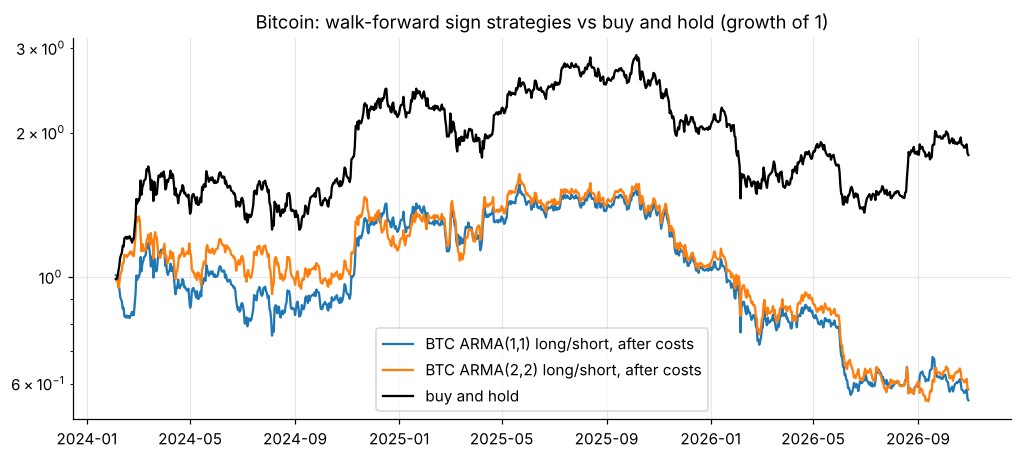

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for k in ["BTC ARMA(1,1)", "BTC ARMA(2,2)"]:
    df, _ = runs[k]
    pos = np.sign(df["forecast"]); cost = np.abs(np.diff(np.r_[0, pos])) * 10 / 1e4
    ax.plot(df.index, np.exp((pos * df["actual"] - cost).cumsum()), label=f"{k} long/short, after costs")
df, _ = runs["BTC ARMA(1,1)"]
ax.plot(df.index, np.exp(df["actual"].cumsum()), c="k", label="buy and hold")
ax.set_yscale("log"); ax.legend(); ax.set_title("Bitcoin: walk-forward sign strategies vs buy and hold (growth of 1)")
plt.savefig(FIG / "06_strategies.png", bbox_inches="tight"); plt.show()

## Would a different model order help?
A common response to a failed backtest is to try more variants and report the best one. Here 16 ARMA orders are run over the same 500-day test period, **before** transaction costs. Even choosing the winner after seeing the results (which is itself a form of look-ahead) would not produce a profitable strategy.

best of 16 on the test period (before costs): ARMA(3,3) -> -4.3% a year
median of the 16: -36.4% a year | worst: -57.2%


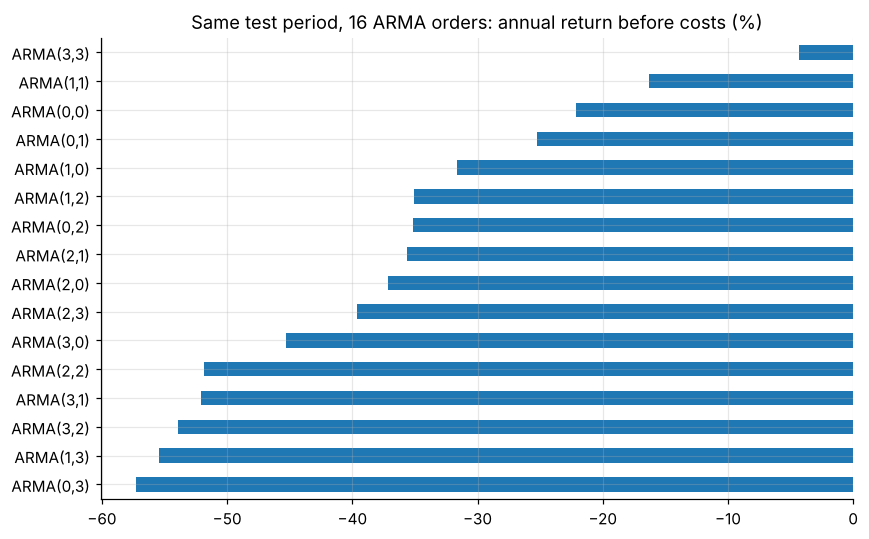

In [4]:
import itertools
test = {}
for p, q in itertools.product(range(4), range(4)):
    df = fc.walk_forward_arma(btc.iloc[-1500:], 500, order=(p, q), train_window=750, refit_every=50)
    test[f"ARMA({p},{q})"] = fc.evaluate(df, cost_bps=0, periods=365)["strategy_ann_ret_%"]
s = pd.Series(test).sort_values()
print(f"best of 16 on the test period (before costs): {s.index[-1]} -> {s.iloc[-1]:.1f}% a year")
print(f"median of the 16: {s.median():.1f}% a year | worst: {s.iloc[0]:.1f}%")
s.plot.barh(figsize=(8, 5), title="Same test period, 16 ARMA orders: annual return before costs (%)")
plt.axvline(0, c="k", lw=.6); plt.tight_layout(); plt.savefig(FIG / "06_selection_bias.png", bbox_inches="tight"); plt.show()

## Findings
* **No model forecasts daily returns better than the historical mean.** Out-of-sample R² is negative for every Bitcoin model and for the four-asset VAR, and no Diebold-Mariano test is significant (all p > 0.12).
* For Bitcoin, AIC on the training window picks ARMA(0,0): the data themselves say there is no exploitable autocorrelation. Forcing ARMA(1,1) or ARMA(2,2) turns that into 237-348 position changes and annual returns of about −20% after costs, against +21% for buy and hold.
* The S&P 500 ARMA(1,1) hit rate of 55.1% is "significant" against 50%, but an always-long position is right 56.0% of the time, so there is no skill. Its Sharpe ratio (0.71) is below buy and hold (1.15).
* Across 16 ARMA orders on the same test window, every one loses money **even before costs** (best −4.3% a year, median −36%).

The practical conclusion: ARMA/VAR models are useful for describing the dynamics and for variance (notebook 3), but daily direction forecasting from past returns alone fails an honest test.